# 📈 **Stock Price Trend Forecasting**
### Project: **Stock Price Trend Prediction using Machine Learning**
**Course:** Machine Learning – Master's Degree in *Intermediari, finanza internazionale e risk management* (Financial Intermediaries, International Finance and Risk Management) – Corporate Finance and Investment Banking

**Author**: Somma Michele

---

## **Projects Objectives**

Build a **ML model** trained to forecast stock price trends, using:

- **Time horizon**: 2013–2023 (training) and 2024–2025 (test)
- **Heterogeneous equity universe**: blue chip, growth/volatile and failed companies
- **Two types of targets**: binary classification and four- class classification.
- **Objective-driven evaluation**: model comparison based on specific trading objectives (e.g., risk aversion vs. alpha capture).


---

### **PHASE 1** - PIPELINE

**Objective**: Convert heterogeneous financial and economic time series into a structured dataset with high informational value.

---

**Pipeline Structure**:
| Section | Description |
|---|---|
| **Setup** | Libraries Installation, import, configuration |
| **Global parameteres** | Centralized parameter definition (Best practice) |
| **Extract** | Raw data download (yfinance, FRED, SimFin) |
| **Transform** | Feature engineering (returns, technical indicators, distress measures) |
| **Merge** | Multi-frequency integration without look-ahead bias |
| **Target** | Construction of target variables (binary and 4-class classification) |
| **Validate** | Data quality, missing values, bias, and class balance analysis |

---

**Methodological pitfalls addressed in this phase**:
| Problem | Solution |
|---|---|
| Frequency mismatch | `merge_asof(direction='backward')` |
| Look-ahead bias | Use of `publish_date`  |
| Survivorship bias | Inclusion of failed and severely distressed companies  |
| Missing not at random (MNAR) | Explicit flag, no mean imputation |
| Timezone inconsistency | Normalization to timezone-free dates |
| Data leakage (train/test) | Strict temporal split at the end of 2023 |

---
>**Final outputs of this phase** : `dataset_train.csv` (2013–2023), `dataset_test.csv` (2024–2025)

---
## SECTION 0 – **Setup and library installation**

In [1]:
# =============================================================================
# LIBRARY INSTALLATION
# yfinance       → market prices from Yahoo Finance
# fredapi        → official API Federal Reserve wrapper
# simfin         → standardized company financial statements
# pandas-datareader → additional utilities for financial data
# =============================================================================
!pip install -q yfinance fredapi simfin pandas-datareader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 2.2 MB/s eta 0:00:00


In [2]:

# ---- Data manipulation ----
import pandas as pd
import numpy as np
import json, time, warnings
warnings.filterwarnings('ignore')

# ---- Financial data ----
import yfinance as yf
from fredapi import Fred
import simfin as sf

# ---- Date ----
from datetime import datetime, timedelta

# ---- Visualization ----
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
import matplotlib.patches as mpatches
from scipy import stats as scipy_stats

# ---- Global Configuration ----
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.4f}'.format)
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

print("✅ All libraries imported successfully")
print(f"   pandas  version: {pd.__version__}")
print(f"   numpy   version: {np.__version__}")
print(f"   yfinance version: {yf.__version__}")

✅ All libraries imported successfully
   pandas  version: 2.2.3
   numpy   version: 2.1.3
   yfinance version: 0.2.66


---
## SECTION 1 – **Global data pipeline parameters**

### Equity universe:

We chose to study three different categories of companies: established and financially sound firms, high-growth/volatile firms, and distressed firms. This three-category structure is **methodologically necessary**:
- Using only surviving firms would create *survivorship bias* →  optimistic model
- Distressed firms provide real distress signals leading, we hope, to more robust models
- Heterogeneity improves generalization

In [15]:
# =============================================================================
# GLOBAL PIPELINE CONFIGURATION
# =============================================================================

# ---- Time horizon ----
# Training: 10 years (2013-2023) → broad historical window, multiple economic cycles
# Test:     2 years  (2024-2025) → out-of-sample period, never seen by the model
START_DATE_TRAIN = '2013-01-01'
END_DATE_TRAIN   = '2023-12-31'
START_DATE_TEST  = '2024-01-01'
END_DATE_TEST    = '2025-12-31'

# Full download window
START_DATE = START_DATE_TRAIN
END_DATE   = END_DATE_TEST

# ---- Forecast horizon ----
# N days in the future to build the target
FORECAST_HORIZON = 21   # 1 training month (stock market)

# =============================================================================
# EQUITY UNIVERSE – Three categories for structural heterogeneity
# =============================================================================

# CATEGORY 1: Blue Chip / Large Cap
# Financially sound companies with long histories, high market capitalization, and established businesses.
# These stocks have relatively clean signals and stable fundamentals..
TICKERS_BLUE_CHIP = [
    # Big Tech (market leadership, robust financial statements)
    'AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META',
    # Finance (Big US banks grandi banche USA, cyclical but resilient)
    'JPM', 'BAC', 'GS', 'WFC',
    # Healthcare (defensive companies, high revenue visibility)
    'JNJ', 'UNH', 'PFE', 'MRK', 'ABBV',
    # Consumer Staples / Discretionary (resilience across economic cycles)
    'WMT', 'HD', 'MCD', 'KO', 'PG',
    # Energy & Industrials
    'XOM', 'CVX', 'CAT', 'BA', 'MMM',
]

# CATEGORY 2: Growth / Volatile
# High-growth companies with uncertain or recently achieved profitability.
# Some are SPACs or post-2015 IPOs → shorter history, higher volatility.
TICKERS_VOLATILE = [
    'NVDA',   # GPU/AI → explosion post-2023
    'TSLA',   # EV → extreme volatility, much followed by retail
    'NFLX',   # Streaming → 2022 crash and recovery
    'AMD',    # Semiconductors → cyclical, Intel challenger
    'UBER',   # Mobility (IPO Mag 2019) → anni di perdite
    'SNAP',   # Social media → never profitable for long
    'ZM',     # Zoom → boom/bust post-pandemic
    'SPCE',   # Virgin Galactic → highly speculative
    'LCID',   # Lucid Motors (SPAC Oct 2021) → EV startup
    'RIVN',   # Rivian (IPO Nov 2021) → EV startup
    'CLOV',   # Clover Health (SPAC Jan 2021) → continuous losses
]

# CATEGORY 3: Distressed
# Companies that experienced severe distress during the training period.
# KEY POINT: explicitly including them mitigates survivorship bias.
# ⚠️ Some may have limited histories: this will be documented.
TICKERS_DISTRESSED = [
    'BBBY',   # Bed Bath & Beyond   → Chapter 11: April 2023
    'HTZ',    # Hertz               → Chapter 11: May 2020 (resurfaces Nov 2021)
    'PTON',   # Peleton             → Post-COVID bubble exploded
    'BYND',   # Beyond Meat         → Serious distress (personally 95% del valore)
    'CVNA',   # Carvana             → Distress and extreme volatility
    'AMC',    # AMC Entertainment   → bankruptcy risk foiled
    'CCL',    # Carnival Corp       → severe distress during COVID
    'GME',    # Gamestop            → Crisis (and memes?)
]

# =============================================================================
# METADATA: ticker → category mapping
# Used for survivorship-bias analysis and visualizations
# =============================================================================
TICKER_CATEGORY = {
    **{t: 'blue_chip'   for t in TICKERS_BLUE_CHIP},
    **{t: 'volatile'    for t in TICKERS_VOLATILE},
    **{t: 'distressed'  for t in TICKERS_DISTRESSED},
}

# Full list (order: blue_chip → volatile → distressed)
TICKERS = TICKERS_BLUE_CHIP + TICKERS_VOLATILE + TICKERS_DISTRESSED

# ---- API Keys ----
FRED_API_KEY   = 'xxxxxxxx'   # Insert your API Key
SIMFIN_API_KEY = 'xxxxxxxx'   # Insert your API Key

# ---- Output files ----
OUTPUT_TRAIN = 'dataset_train.csv'    # Periodo: 2013-2023
OUTPUT_TEST  = 'dataset_test.csv'     # Periodo: 2024-2025
OUTPUT_FULL  = 'dataset_panel_full.csv'

# ---- Configuration summary ----
print("📋  Pipeline configuration:")
print(f"   Training period : {START_DATE_TRAIN} → {END_DATE_TRAIN}")
print(f"   Test period:     {START_DATE_TEST}  → {END_DATE_TEST}")
print(f"   Forecast horizon: {FORECAST_HORIZON} giorni")
print(f"   Total ticker :  {len(TICKERS)}")
print(f"     → Blue Chip:    {len(TICKERS_BLUE_CHIP)}")
print(f"     → Volatile:     {len(TICKERS_VOLATILE)}")
print(f"     → Distressed:   {len(TICKERS_DISTRESSED)}")
print(f"   Output:           {OUTPUT_TRAIN}, {OUTPUT_TEST}")

📋  Pipeline configuration:
   Training period : 2013-01-01 → 2023-12-31
   Test period:     2024-01-01  → 2025-12-31
   Forecast horizon: 21 giorni
   Total ticker :  43
     → Blue Chip:    24
     → Volatile:     11
     → Distressed:   8
   Output:           dataset_train.csv, dataset_test.csv


---
## SECTION TWO – EXTRACT: Data collection from sources

The **Extract** phase downloads the raw data while keeping each dataset separate.
At this stage, no merge or transformation is performed: we first collect the data and process it only afterwards.

---

### 2.1 – Stock prices from yfinance (frequency: daily)

**N.B.**: It should be noted that the original equity universe included bankrupt companies to mitigate survivorship bias. However, because the yfinance library does not provide historical data for delisted tickers, the dataset composition had to be revised. Consequently, the final classification category was redefined by replacing bankrupt companies with those experiencing severe financial distress, thereby preserving the original objective of representing the extreme risk class.

In [4]:
# =============================================================================
# STEP 2.1 – DOWNLOAD PRICES FROM YFINANCE
# =============================================================================
#
# Two-level download strategy:
# 1. Batch download (all tickers together)
# 2. If the batch fails: fallback to individual tickers
#
# Delisted tickers: yfinance accepts them and returns available data.
# Final dataset -> \"ragged\" (= different lengths across tickers)
# =============================================================================

def download_prices_robust(tickers, start, end, batch_size=15):
    """
Download OHLCV prices for a heterogeneous universe of tickers, including delisted ones.

Strategy:
- Batch download for efficiency
- Single-ticker fallback in case of partial errors
- Returns a long-format dataset (ticker × date) with category annotation

Parameters
----------
tickers     : list of ticker symbols
start, end  : start/end dates in 'YYYY-MM-DD' format
batch_size  : number of tickers per batch (default 15)

Returns
-------
prices_long : pd.DataFrame in long format
failed      : list of tickers for which the download failed completely
"""
    all_frames = []
    failed     = []

    n_batches = (len(tickers) + batch_size - 1) // batch_size
    print(f"   Download in {n_batches} batch da {batch_size} ticker ciascuno...")

    for i in range(0, len(tickers), batch_size):
        batch = tickers[i : i + batch_size]
        batch_num = i // batch_size + 1

        try:
            raw = yf.download(
                tickers     = batch,
                start       = start,
                end         = end,
                auto_adjust = True,   # Adjusted for dividends and splits
                progress    = True,
                group_by    = 'ticker'
            )

            if raw.empty:
                print(f"   ⚠️  Batch {batch_num}: nessun dato restituito")
                failed.extend(batch)
                continue

            # Case handling with only one ticker (yf doesn't create MultiInde)
            if len(batch) == 1:
                raw.columns = pd.MultiIndex.from_product([['Close','High','Low','Open','Volume'],
                                                           batch])

            # Stack: from wide (field, ticker) to long (ticker, date, fields)
            long = raw.stack(level=0, future_stack=True).reset_index()
            long.columns.name = None
            all_frames.append(long)
            print(f"   ✅ Batch {batch_num}/{n_batches}: {len(batch)} ticker, "
                  f"{len(long):,} righe")

        except Exception as e:
            print(f"   ⚠️  Batch {batch_num} fallito ({e}) → fallback singolo...")
            for ticker in batch:
                try:
                    raw_single = yf.download(ticker, start=start, end=end,
                                              auto_adjust=True, progress=False)
                    if not raw_single.empty:
                        raw_single.insert(0, 'Ticker', ticker)
                        raw_single = raw_single.reset_index()
                        all_frames.append(raw_single)
                except Exception:
                    failed.append(ticker)

    if not all_frames:
        raise ValueError("No data downloaded. Check your connection or tickers..")

    # Concatenation and standardization columns
    prices = pd.concat(all_frames, ignore_index=True)

    # Rename columns flexibly (manages yfinance variations)
    rename_map = {}
    for col in prices.columns:
        col_lower = str(col).lower()
        if col_lower in ('ticker', 'symbol'):     rename_map[col] = 'ticker'
        elif col_lower == 'date':                  rename_map[col] = 'date'
        elif col_lower == 'close':                 rename_map[col] = 'close'
        elif col_lower == 'open':                  rename_map[col] = 'open'
        elif col_lower == 'high':                  rename_map[col] = 'high'
        elif col_lower == 'low':                   rename_map[col] = 'low'
        elif col_lower == 'volume':                rename_map[col] = 'volume'
    prices = prices.rename(columns=rename_map)

    # Cleaning: We remove unhelpful columns
    keep_cols = [c for c in ['ticker','date','open','high','low','close','volume']
                 if c in prices.columns]
    prices = prices[keep_cols].copy()

    # Date Normalization: We Remove Timezone (PITFALL #5)
    prices['date'] = pd.to_datetime(prices['date']).dt.tz_localize(None).dt.normalize()

    # We remove rows without price (possible in pre-IPO or post-delisting periods)
    prices = prices.dropna(subset=['close'])

    # We order for (ticker, date) → fundamental for time-series operations
    prices = prices.sort_values(['ticker', 'date']).reset_index(drop=True)

    return prices, failed


# =============================================================================
# DOWNLOAD EXECUTION
# =============================================================================
print("📥 Start downloading prices from Yahoo Finance...")
print(f"   Period: {START_DATE} → {END_DATE}")
print(f"   Ticker:  {len(TICKERS)} ({len(TICKERS_BLUE_CHIP)} blue_chip + "
      f"{len(TICKERS_VOLATILE)} volatile + {len(TICKERS_DISTRESSED)} distressed)\n")

prices_long, failed_tickers = download_prices_robust(TICKERS, START_DATE, END_DATE)

print(f"\n✅ Download completed")
print(f"   Total row:    {len(prices_long):,}")
print(f"   Tickers downloaded : {prices_long['ticker'].nunique()} / {len(TICKERS)}")
print(f"   Effective period: {prices_long['date'].min().date()} → "
      f"{prices_long['date'].max().date()}")
if failed_tickers:
    print(f"   ⚠️  Failed tickers: {failed_tickers}")
prices_long.head(5)


📥 Start downloading prices from Yahoo Finance...
   Period: 2013-01-01 → 2025-12-31
   Ticker:  43 (24 blue_chip + 11 volatile + 8 distressed)

   Download in 3 batch da 15 ticker ciascuno...


[*********************100%***********************]  15 of 15 completed


   ✅ Batch 1/3: 15 ticker, 49,035 righe


[*********************100%***********************]  15 of 15 completed


   ✅ Batch 2/3: 15 ticker, 49,035 righe


[*********************100%***********************]  13 of 13 completed
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['BBBY']: YFPricesMissingError('possibly delisted; no price data found  (1d 2013-01-01 -> 2025-12-31) (Yahoo error = "Data doesn\'t exist for startDate = 1357016400, endDate = 1767157200")')


   ✅ Batch 3/3: 13 ticker, 42,497 righe

✅ Download completed
   Total row:    119,067
   Tickers downloaded : 42 / 43
   Effective period: 2013-01-02 → 2025-12-30


,ticker,date,open,high,low,close,volume
0,AAPL,2013-01-02,16.7116,16.7473,16.3438,16.5671,"560,518,000.0000"
1,AAPL,2013-01-03,16.5324,16.5864,16.3248,16.3580,"352,965,200.0000"
2,AAPL,2013-01-04,16.2032,16.2533,15.8670,15.9024,"594,333,600.0000"
3,AAPL,2013-01-07,15.7515,15.9718,15.5463,15.8088,"484,156,400.0000"
4,AAPL,2013-01-08,15.9690,16.0499,15.7288,15.8514,"458,707,200.0000"


In [5]:
# =============================================================================
# STEP 2.1b – ADD METADATA AND ANALYZE COVERAGE BY CATEGORY
# =============================================================================
#
# Add ticker category to the dataset.
# Analyze coverage to identify tickers with limited history.
# (recent SPACs/IPOs) → these have fewer training years available.
# =============================================================================

# Added category
prices_long['category'] = prices_long['ticker'].map(TICKER_CATEGORY).fillna('unknown')

# Coverage analysis by ticker
coverage = prices_long.groupby(['ticker', 'category']).agg(
    n_giorni    = ('date', 'count'),
    data_inizio = ('date', 'min'),
    data_fine   = ('date', 'max'),
).reset_index()

coverage['anni_copertura'] = (coverage['data_fine'] - coverage['data_inizio']).dt.days / 365.25
coverage = coverage.sort_values(['category', 'anni_copertura'])

print("📊 Data coverage by ticker and category:")
print("=" * 75)
for cat in ['blue_chip', 'volatile', 'distressed']:
    sub = coverage[coverage['category'] == cat]
    print(f"\n  [{cat.upper()}] – {len(sub)} ticker")
    print(f"  {'Ticker':<8} {'Inizio':<12} {'Fine':<12} {'Anni':>6}  {'Giorni':>7}")
    print(f"  {'-'*55}")
    for _, row in sub.iterrows():
        flag = ' ⚠️ storia breve' if row['anni_copertura'] < 5 else ''
        print(f"  {row['ticker']:<8} {str(row['data_inizio'].date()):<12} "
              f"{str(row['data_fine'].date()):<12} {row['anni_copertura']:>6.1f}  "
              f"{row['n_giorni']:>7,}{flag}")

print(f"\n📌 Ticker with history < 5 anni: "
      f"{len(coverage[coverage['anni_copertura'] < 5])}")
print(f"   → They will have less training data but are methodologically sound.")

📊 Data coverage by ticker and category:

  [BLUE_CHIP] – 24 ticker
  Ticker   Inizio       Fine           Anni   Giorni
  -------------------------------------------------------
  AAPL     2013-01-02   2025-12-30     13.0    3,269
  ABBV     2013-01-02   2025-12-30     13.0    3,269
  AMZN     2013-01-02   2025-12-30     13.0    3,269
  BA       2013-01-02   2025-12-30     13.0    3,269
  BAC      2013-01-02   2025-12-30     13.0    3,269
  CAT      2013-01-02   2025-12-30     13.0    3,269
  CVX      2013-01-02   2025-12-30     13.0    3,269
  GOOGL    2013-01-02   2025-12-30     13.0    3,269
  GS       2013-01-02   2025-12-30     13.0    3,269
  HD       2013-01-02   2025-12-30     13.0    3,269
  JNJ      2013-01-02   2025-12-30     13.0    3,269
  JPM      2013-01-02   2025-12-30     13.0    3,269
  KO       2013-01-02   2025-12-30     13.0    3,269
  MCD      2013-01-02   2025-12-30     13.0    3,269
  META     2013-01-02   2025-12-30     13.0    3,269
  MMM      2013-01-02   202

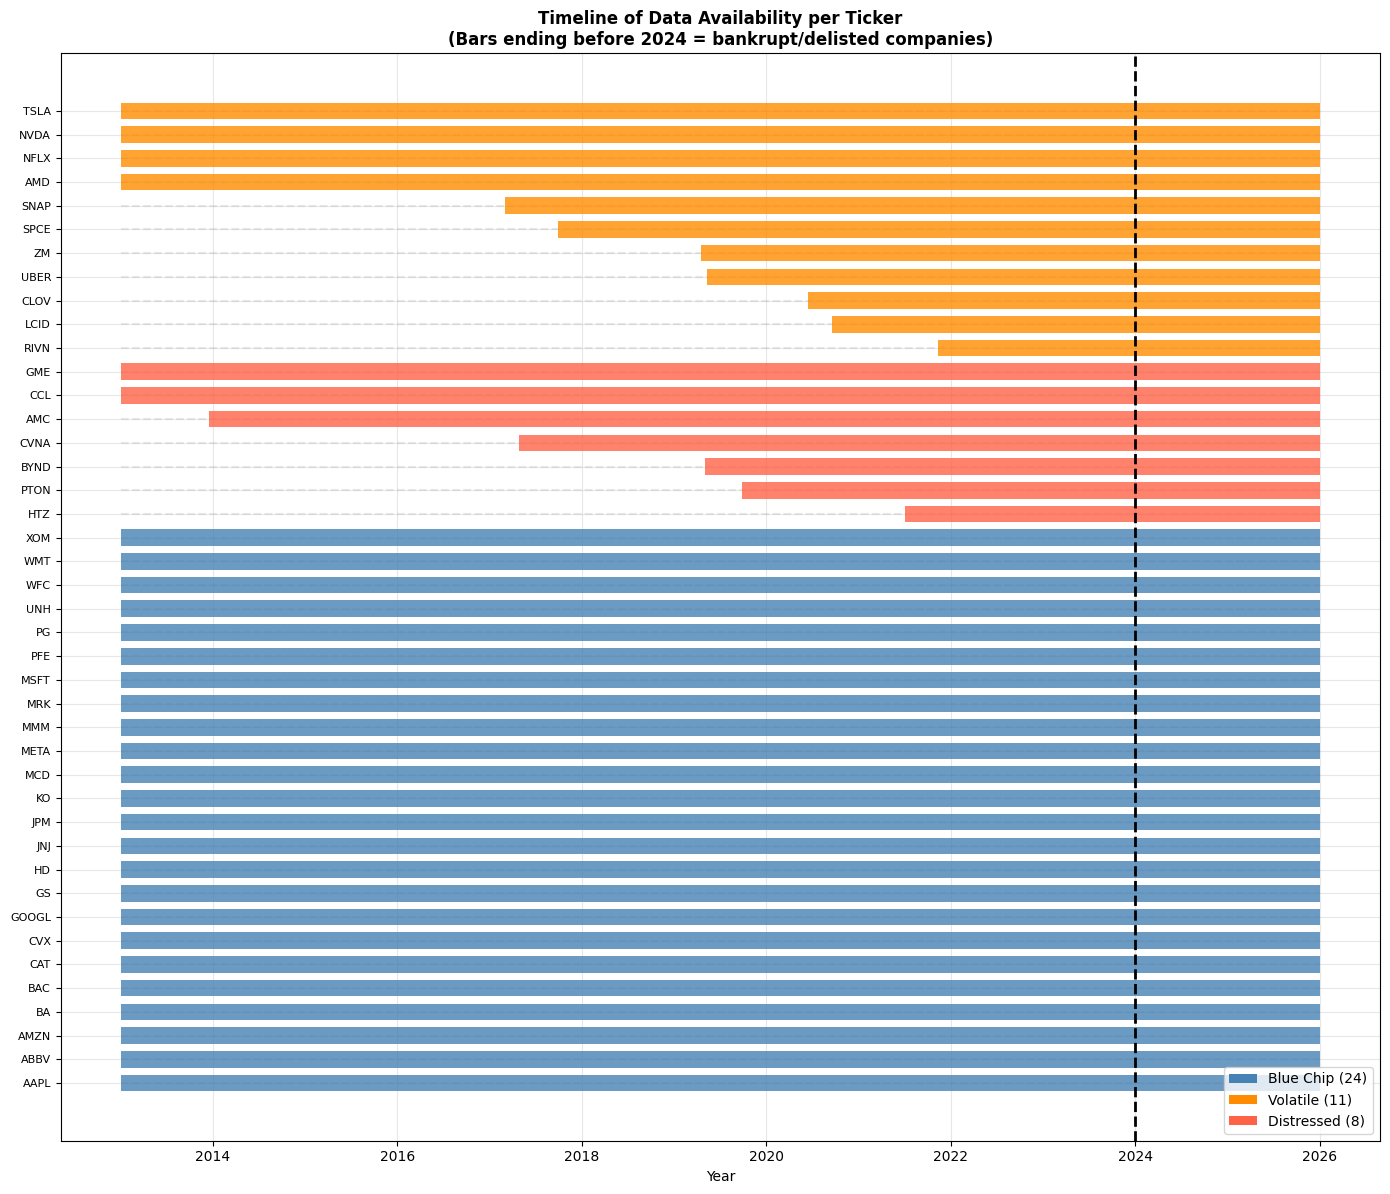

💡 Tickers extend until 2026 because the dataset includes all available prices up to the present
   Differences in bar length mainly reflect different IPO dates or data availability.


In [6]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(14, max(8, len(TICKERS) * 0.28)))

colors = {'blue_chip': 'steelblue', 'volatile': 'darkorange', 'distressed': 'tomato'}
tickers_sorted = coverage.sort_values(['category', 'data_inizio'], ascending=[True, False])

# Define the global start and end bounds for our timeline (2013 - 2026)
global_start = pd.Timestamp('2013-01-01')
global_end = pd.Timestamp('2026-01-01')

for i, (_, row) in enumerate(tickers_sorted.iterrows()):
    color = colors.get(row['category'], 'gray')

    # Light gray dashed line indicating the full timeline (missing data track)
    ax.hlines(y=i, xmin=global_start, xmax=global_end,
              color='lightgray', linestyle='--', alpha=0.5, zorder=1)

    # Original colored bar for actual data availability
    ax.barh(i, (row['data_fine'] - row['data_inizio']).days,
            left=row['data_inizio'], height=0.7,
            color=color, alpha=0.8, linewidth=0, zorder=2)

ax.set_yticks(range(len(tickers_sorted)))
ax.set_yticklabels(tickers_sorted['ticker'].tolist(), fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator(2))

# Train/Test split line
split_date = pd.Timestamp('2024-01-01')
ax.axvline(x=split_date, color='black', linestyle='--', lw=2,
           label='Split Train/Test', zorder=3)

# Legend
legend_elements = [
    Patch(facecolor='steelblue',  label=f'Blue Chip ({len(TICKERS_BLUE_CHIP)})'),
    Patch(facecolor='darkorange', label=f'Volatile ({len(TICKERS_VOLATILE)})'),
    Patch(facecolor='tomato',     label=f'Distressed ({len(TICKERS_DISTRESSED)})'),
]
ax.legend(handles=legend_elements, loc='lower right')
ax.set_title('Timeline of Data Availability per Ticker\n'
             '(Bars ending before 2024 = bankrupt/delisted companies)',
             fontweight='bold', fontsize=12)
ax.set_xlabel('Year')
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("💡 Tickers extend until 2026 because the dataset includes all available prices up to the present")
print("   Differences in bar length mainly reflect different IPO dates or data availability.")

### 2.2 – Macro Variables from FRED (frequency: Monthly/Daily)

FRED (Federal Reserve Economic Data) offers economic series to capture the **macro context**.
Macro variables are common to all tickers → no 'by' in the next merge.

Variables selected for relevance in pricing models:
| FRED Code | Variable | Freq. | Ratio |
|---|---|---|---|
| `TB3MS` | T-Bill 3M | Monthly | Risk-free rate (CAPM baseline) |
| `GS10` | Treasury 10Y | Monthly | Long-term rate, term premium |
| `VIXCLS` | VIX | Daily | Implicit volatility, risk-off/on |
| `CPIAUCSL` | CPI | Monthly | Inflation, purchase power |
| `UNRATE` | Unemployment | Monthly | Economic cycle |
| `DCOILWTICO` | Crude Oil WTI | Daily | Input cost, macro risk |
| `SP500` | S&P 500 Index | Daily | Market benchmark |

In [12]:
# =============================================================================
# STEP 2.2 – MACRO DATA FROM FRED
# =============================================================================

def download_fred_data(api_key, start, end):
    """

Download the main macroeconomic series from the Federal Reserve (FRED).

Downloaded variables (7 series, mixed frequencies):
- Interest rates: TB3MS, GS10
- Volatility: VIXCLS (daily)
- Prices: CPIAUCSL, DCOILWTICO (daily)
- Employment: UNRATE
- Market: SP500 (daily)
Returns

-------
pd.DataFrame with columns: date, vix, tbill_3m, treasury_10y,
                           cpi, unemployment, oil_wti, sp500_level
and derived variables: cpi_yoy, term_spread
"""

    fred = Fred(api_key=api_key)

    series_map = {
        'tbill_3m':     'TB3MS',
        'treasury_10y': 'GS10',
        'vix':          'VIXCLS',
        'cpi':          'CPIAUCSL',
        'unemployment': 'UNRATE',
        'oil_wti':      'DCOILWTICO',
        'sp500_level':  'SP500',
    }

    frames = []
    for name, code_fred in series_map.items():
        try:
            s = fred.get_series(code_fred, observation_start=start, observation_end=end)
            if s is not None and not s.empty:
                s.name = name
                frames.append(s)
                print(f"   ✅ {name} ({code_fred}): {len(s)} observations")
            else:
                print(f"   ☢☢ {name} ({code_fred}): No data returned or empty series.")
                frames.append(pd.Series(dtype=float, name=name)) # Append empty series
        except ValueError as e:
            print(f"   ❌ {name} ({code_fred}): error while downloading - {e}")
            frames.append(pd.Series(dtype=float, name=name)) # Append empty series
        except Exception as e:
            print(f"   ❌ {name} ({code_fred}): unexpected error while downloading - {e}")
            frames.append(pd.Series(dtype=float, name=name))

    df_macro = pd.concat(frames, axis=1).reset_index()
    df_macro.rename(columns={'index': 'date'}, inplace=True)
    df_macro['date'] = pd.to_datetime(df_macro['date']).dt.tz_localize(None)

    # Derived variables
    df_macro['cpi_yoy']     = df_macro['cpi'].pct_change(12) * 100
    df_macro['term_spread'] = df_macro['treasury_10y'] - df_macro['tbill_3m']
    df_macro['oil_ret_1m']  = df_macro['oil_wti'].pct_change(21)   # rendimento mensile oil
    df_macro['sp500_ret_1m']= df_macro['sp500_level'].pct_change(21)

    return df_macro

print("Download macro data from FRED...")
df_macro = download_fred_data(FRED_API_KEY, START_DATE, END_DATE)

print(f"\n✅ Dataset macro is ready: {df_macro.shape}")
print(f"   Columns: {list(df_macro.columns)}")
df_macro.tail(4)

Download macro data from FRED...
   ✅ tbill_3m (TB3MS): 156 observations
   ✅ treasury_10y (GS10): 156 observations
   ✅ vix (VIXCLS): 3392 observations
   ✅ cpi (CPIAUCSL): 156 observations
   ✅ unemployment (UNRATE): 156 observations
   ✅ oil_wti (DCOILWTICO): 3392 observations
   ✅ sp500_level (SP500): 2423 observations

✅ Dataset macro is ready: (3436, 12)
   Columns: ['date', 'tbill_3m', 'treasury_10y', 'vix', 'cpi', 'unemployment', 'oil_wti', 'sp500_level', 'cpi_yoy', 'term_spread', 'oil_ret_1m', 'sp500_ret_1m']


,date,tbill_3m,treasury_10y,vix,cpi,unemployment,oil_wti,sp500_level,cpi_yoy,term_spread,oil_ret_1m,sp500_ret_1m
3432,2025-12-26,NaN,NaN,13.6000,NaN,NaN,56.6000,"6,929.9400",0.0000,NaN,-0.0376,0.0172
3433,2025-12-29,NaN,NaN,14.2000,NaN,NaN,57.8900,"6,905.7400",0.0000,NaN,-0.0118,0.0083
3434,2025-12-30,NaN,NaN,14.3300,NaN,NaN,57.7900,"6,896.2400",0.0000,NaN,-0.0282,0.0123
3435,2025-12-31,NaN,NaN,14.9500,NaN,NaN,57.2600,"6,845.5000",0.0000,NaN,-0.0264,0.0024


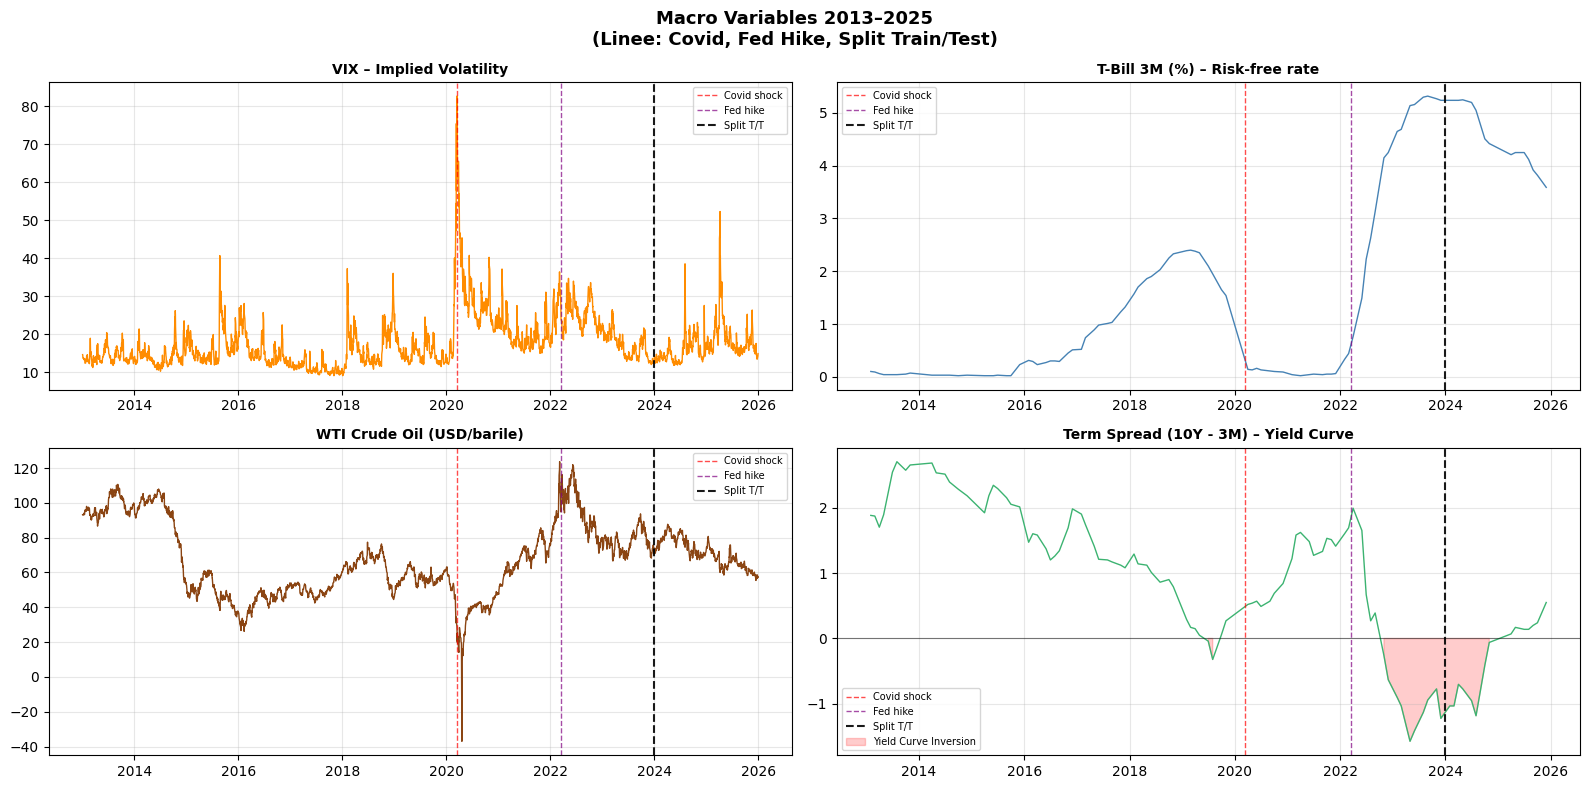

💡 The inversion of the yield curve (term_spread < 0) in 2022-2023 is 
   a classic recession signal → feature with high predictive value.


In [13]:
# =============================================================================
# VISUALIZATION: Main macro series (2013-2025)
# =============================================================================
# We visualized the 4 most important macro variables for the model.
# This sanity check confirms that the data captures key events:
# - Covid (2020): spike VIX, rate collapse e oil
# - Hiking cycle Fed (2022-2023): rate hike, high inflation
# =============================================================================

df_macro_daily = df_macro.dropna(subset=['vix'])

fig, axes = plt.subplots(2, 2, figsize=(16, 8))

plot_specs = [
    ('vix',          'VIX – Implied Volatility',          'axes[0,0]', 'darkorange'),
    ('tbill_3m',     'T-Bill 3M (%) – Risk-free rate',      'axes[0,1]', 'steelblue'),
    ('oil_wti',      'WTI Crude Oil (USD/barile)',            'axes[1,0]', 'saddlebrown'),
    ('term_spread',  'Term Spread (10Y - 3M) – Yield Curve', 'axes[1,1]', 'mediumseagreen'),
]

ax_list = [axes[0,0], axes[0,1], axes[1,0], axes[1,1]]
for ax, (col, title, _, color) in zip(ax_list, plot_specs):
    data = df_macro_daily[['date', col]].dropna()
    ax.plot(data['date'], data[col], linewidth=1, color=color)
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.axvline(pd.Timestamp('2020-03-15'), color='red', ls='--', lw=1, alpha=0.7,
               label='Covid shock')
    ax.axvline(pd.Timestamp('2022-03-16'), color='purple', ls='--', lw=1, alpha=0.7,
               label='Fed hike')
    ax.axvline(pd.Timestamp('2024-01-01'), color='black', ls='--', lw=1.5, alpha=0.9,
               label='Split T/T')
    if col == 'term_spread':
        ax.axhline(0, color='black', ls='-', lw=0.8, alpha=0.5)
        ax.fill_between(data['date'], data[col], 0,
                        where=data[col] < 0, alpha=0.2, color='red',
                        label='Yield Curve Inversion')
    ax.legend(fontsize=7)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.suptitle('Macro Variables 2013–2025\n(Linee: Covid, Fed Hike, Split Train/Test)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 The inversion of the yield curve (term_spread < 0) in 2022-2023 is ")
print("   a classic recession signal → feature with high predictive value.")

### 2.3 – Business fundamentals from SimFin (frequency: Quarterly/Annual)

SimFin provides standardized balance sheets with separation between `report_date` and `publish_date`.
> **⚠️ Anti-look-ahead bias key**: We always use the 'publish_date' (when the data was *available* to the market), never the 'report_date' (end of the accounting quarter).

In [16]:
# =============================================================================
# STEP 2.3 – FUNDAMENTALS FROM SIMFIN
# =============================================================================
#
# NOTE for distressed tickers: SimFin may not have data for some delisted companies
# =============================================================================

def download_simfin_fundamentals(api_key, tickers, start, end):
    """
    Download financial statement fundamentals from SimFin.
    Combines the Income Statement and Balance Sheet into a single panel.
    Returns

    -------
    pd.DataFrame with columns: ticker, publish_date, revenue, net_income,
    ebit, total_assets, equity, total_liabilities
    """
    sf.set_api_key(api_key)
    sf.set_data_dir('~/simfin_data/')

    print("   Download Income Statement (annual)...")
    df_income  = sf.load_income(variant='annual', market='us').reset_index()

    print("   Download Balance Sheet (annual)...")
    df_balance = sf.load_balance(variant='annual', market='us').reset_index()

    df_income  = df_income[df_income['Ticker'].isin(tickers)]
    df_balance = df_balance[df_balance['Ticker'].isin(tickers)]

    inc_cols = [c for c in ['Ticker','Publish Date','Report Date',
                             'Revenue','Net Income','Operating Income',
                             'Shares (Basic)'] if c in df_income.columns]
    bal_cols = [c for c in ['Ticker','Publish Date','Total Assets',
                             'Total Equity','Total Liabilities',
                             'Total Current Assets','Total Current Liabilities',
                             'Retained Earnings'] if c in df_balance.columns]

    df_i = df_income[inc_cols].copy()
    df_b = df_balance[bal_cols].copy()

    df_fund = pd.merge(df_i, df_b, on=['Ticker','Publish Date'],
                       how='inner', suffixes=('_inc','_bal'))

    df_fund = df_fund.rename(columns={
        'Ticker':                   'ticker',
        'Publish Date':             'publish_date',
        'Report Date':              'report_date',
        'Revenue':                  'revenue',
        'Net Income':               'net_income',
        'Operating Income':         'ebit',
        'Total Assets':             'total_assets',
        'Total Equity':             'equity',
        'Total Liabilities':        'total_liabilities',
        'Total Current Assets':     'current_assets',
        'Total Current Liabilities':'current_liabilities',
        'Retained Earnings':        'retained_earnings',
        'Shares (Basic)':           'shares',
    })

    df_fund['publish_date'] = pd.to_datetime(
        df_fund['publish_date']).dt.tz_localize(None)
    df_fund = df_fund[
        (df_fund['publish_date'] >= pd.Timestamp(start)) &
        (df_fund['publish_date'] <= pd.Timestamp(end))
    ]

    print(f"   ✅ Fundamentals downloaded: {df_fund.shape}")
    return df_fund

print("📥 Fundamentals downloaded from SimFin...")
df_fundamentals = download_simfin_fundamentals(
    SIMFIN_API_KEY, TICKERS, START_DATE, END_DATE)
print(f"\n✅ Fundamentals dataset ready: {df_fundamentals.shape}")
print(f"   Ticker with fundamentals: {df_fundamentals['ticker'].nunique()}")
df_fundamentals.head(4)

📥 Fundamentals downloaded from SimFin...
   Download Income Statement (annual)...
Dataset "us-income-annual" not on disk.
- Downloading ... 100.0%
- Extracting zip-file ... Done!
- Loading from disk ... Done!
   Download Balance Sheet (annual)...
Dataset "us-balance-annual" not on disk.
- Downloading ... 100.0%
- Extracting zip-file ... Done!
- Loading from disk ... Done!
   ✅ Fundamentals downloaded: (179, 12)

✅ Fundamentals dataset ready: (179, 12)
   Ticker with fundamentals: 38


,ticker,publish_date,report_date,revenue,net_income,shares,total_assets,equity,total_liabilities,current_assets,current_liabilities,retained_earnings
0,AAPL,2021-10-29,2021-09-30,"365,817,000,000.0000",94680000000,"16,391,724,000.0000",351002000000,63090000000,"287,912,000,000.0000","134,836,000,000.0000","125,481,000,000.0000","5,562,000,000.0000"
1,AAPL,2022-10-28,2022-09-30,"394,328,000,000.0000",99803000000,"16,215,963,000.0000",352755000000,50672000000,"302,083,000,000.0000","135,405,000,000.0000","153,982,000,000.0000","-3,068,000,000.0000"
2,AAPL,2023-11-03,2023-09-30,"383,285,000,000.0000",96995000000,"15,744,231,000.0000",352583000000,62146000000,"290,437,000,000.0000","143,566,000,000.0000","135,486,000,000.0000","-214,000,000.0000"
3,AAPL,2024-11-01,2024-09-30,"391,035,000,000.0000",93736000000,"15,343,783,000.0000",364980000000,56950000000,"308,030,000,000.0000","152,987,000,000.0000","165,480,000,000.0000","-19,154,000,000.0000"


---
## SECTION 3 – TRANSFORM: Feature Engineering

The **Transform** phase builds all features from the pricing dataset.
We organize into four groups:
1. **Returns and momentum** – capture the direction of the trend
2. **Technical indicators** – RSI, MACD, Bollinger Bands, ATR
3. **Volatility and volume** – risk measures and market activities
4. **Distress indicator** – Altman Z-Score proxy (added after merge)

> **Technical note**: All rolling operations use 'groupby('ticker')' to avoid "contaminating" the calculation with data from other tickers. A common error in panel datasets!

In [17]:
# =============================================================================
# STEP 3.1 – MOMENTUM RETURNS AND INDICATORS
# =============================================================================
#
# Log-returns (vs simple returns):
# - Additives over time: log(P_t/P_0) = Σ log(P_i/P_{i-1})
# - More stable numerically for long periods
# - Best approximated by the normal distribution
#
# We use groupby('ticker').transform() for rolling operations to ensure
# that the rolling window does not "jump" from one ticker to another in the DataFrame.
# =============================================================================

print("⚙️  Calculating returns and momentum indicators...")

# ---- Log-returns ----
# .shift(1) to denominator equals pct_change with previous day
prices_long['log_ret_1d']  = prices_long.groupby('ticker')['close'].transform(
    lambda x: np.log(x / x.shift(1))
)
prices_long['log_ret_5d']  = prices_long.groupby('ticker')['close'].transform(
    lambda x: np.log(x / x.shift(5))
)
prices_long['log_ret_21d'] = prices_long.groupby('ticker')['close'].transform(
    lambda x: np.log(x / x.shift(21))
)
prices_long['log_ret_63d'] = prices_long.groupby('ticker')['close'].transform(
    lambda x: np.log(x / x.shift(63))   # ~3 mesi
)

# ---- Momentum ----
# It's one of the most documented risk factors in finance
# (Jegadeesh & Titman 1993): cumulative yield of the last K months
prices_long['mom_6m']  = prices_long.groupby('ticker')['close'].transform(
    lambda x: np.log(x / x.shift(126))  # ~6 mesi
)
prices_long['mom_12m'] = prices_long.groupby('ticker')['close'].transform(
    lambda x: np.log(x / x.shift(252))  # ~12 mesi
)

# ---- Moving Averages ----
prices_long['sma_20']  = prices_long.groupby('ticker')['close'].transform(
    lambda x: x.rolling(20,  min_periods=10).mean()
)
prices_long['sma_50']  = prices_long.groupby('ticker')['close'].transform(
    lambda x: x.rolling(50,  min_periods=25).mean()
)
prices_long['sma_200'] = prices_long.groupby('ticker')['close'].transform(
    lambda x: x.rolling(200, min_periods=100).mean()
)

# Price position relative to MAs
prices_long['price_to_sma50']  = prices_long['close'] / prices_long['sma_50']  - 1
prices_long['price_to_sma200'] = prices_long['close'] / prices_long['sma_200'] - 1

# Golden Cross / Death Cross signal
# Golden Cross (SMA50 > SMA200): classic bullish signal
prices_long['golden_cross'] = (
    prices_long['sma_50'] > prices_long['sma_200']
).astype(int)

print("✅ Returns and momentum calculated:")
ret_cols = ['log_ret_1d', 'log_ret_5d', 'log_ret_21d', 'log_ret_63d',
            'mom_6m', 'mom_12m', 'price_to_sma50', 'price_to_sma200', 'golden_cross']
print(f"   Added features : {ret_cols}")
print(f"   Dataset: {prices_long.shape}")

⚙️  Calculating returns and momentum indicators...
✅ Returns and momentum calculated:
   Added features : ['log_ret_1d', 'log_ret_5d', 'log_ret_21d', 'log_ret_63d', 'mom_6m', 'mom_12m', 'price_to_sma50', 'price_to_sma200', 'golden_cross']
   Dataset: (119067, 20)


In [18]:
# =============================================================================
# STEP 3.2 – TECHNICAL INDICATORS: RSI, MACD, BOLLINGER BANDS, ATR
# =============================================================================
#
# Manual implementation with pandas (no external libraries required).
# Each indicator is calculated for each ticker separately via groupby + transform.
# =============================================================================

def compute_rsi(close_series, window=14):
    """
    RSI (Relative Strength Index) of Wilder.

   It measures the speed and amplitude of price changes.
    RSI > 70 → overbought (possible bearish reversal)
    RSI < 30 → oversold   (possible bullish reversal)
    """
    delta = close_series.diff()
    gain  = delta.clip(lower=0)
    loss  = (-delta).clip(lower=0)

    # Exponential moving average (Wilder smoothing: α = 1/window)
    avg_gain = gain.ewm(alpha=1/window, min_periods=window, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/window, min_periods=window, adjust=False).mean()

    rs  = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - (100 / (1 + rs))
    return rsi


def compute_macd(close_series, fast=12, slow=26, signal=9):
    """
    MACD (Moving Average Convergence Divergence).

    Capture changes in the strength, direction, and duration of a trend.
    - macd_line = EMA(12) - EMA(26)
    - signal_line = EMA(9) of macd_line
    - histogram = macd_line - signal_line
    """
    ema_fast   = close_series.ewm(span=fast, adjust=False).mean()
    ema_slow   = close_series.ewm(span=slow, adjust=False).mean()
    macd_line  = ema_fast - ema_slow
    signal_line= macd_line.ewm(span=signal, adjust=False).mean()
    histogram  = macd_line - signal_line
    return macd_line, signal_line, histogram


def compute_bollinger_bands(close_series, window=20, n_std=2):
    """
    Bande di Bollinger.

    They measure the position of the price with respect to its recent volatility.
    - bb_position: 0 = to the lower band, 1 = to the higher band
    - bb_width: measure of implied volatility in the bands
    """
    rolling = close_series.rolling(window, min_periods=window//2)
    bb_mid  = rolling.mean()
    bb_std  = rolling.std()
    bb_up   = bb_mid + n_std * bb_std
    bb_dn   = bb_mid - n_std * bb_std
    bb_pos  = (close_series - bb_dn) / (bb_up - bb_dn).replace(0, np.nan)
    bb_width= (bb_up - bb_dn) / bb_mid.replace(0, np.nan)
    return bb_pos, bb_width


def compute_atr(high, low, close, window=14):
    """
    ATR (Average True Range).

    It measures market volatility as the average range of recent trading sessions.
It does not indicate direction, only the magnitude of the changes.
    """
    prev_close = close.shift(1)
    tr = pd.concat([
        high - low,
        (high - prev_close).abs(),
        (low  - prev_close).abs(),
    ], axis=1).max(axis=1)
    atr = tr.ewm(span=window, adjust=False).mean()
    return atr / close  # Normalize for price → comparable between stocks


print("⚙️  Calculation of technical indicators (RSI, MACD, Bollinger, ATR)...")
print("   (Groupby operation for ticker – may take a few minutes)\n")

# --- Application for ticker ---
groups   = prices_long.groupby('ticker', sort=False)
rsi_list, macd_list, sig_list, hist_list = [], [], [], []
bbpos_list, bbwid_list, atr_list = [], [], []

for ticker, grp in groups:
    grp = grp.sort_values('date')
    close = grp['close']
    high  = grp['high']
    low   = grp['low']

    rsi_list.append(compute_rsi(close))

    macd_l, sig_l, hist_l = compute_macd(close)
    macd_list.append(macd_l)
    sig_list.append(sig_l)
    hist_list.append(hist_l)

    bbpos, bbwid = compute_bollinger_bands(close)
    bbpos_list.append(bbpos)
    bbwid_list.append(bbwid)

    atr_list.append(compute_atr(high, low, close))

prices_long['rsi_14']          = pd.concat(rsi_list)
prices_long['macd']            = pd.concat(macd_list)
prices_long['macd_signal']     = pd.concat(sig_list)
prices_long['macd_hist']       = pd.concat(hist_list)
prices_long['bb_position']     = pd.concat(bbpos_list)   # 0= inf, 1= sup
prices_long['bb_width']        = pd.concat(bbwid_list)   # relative width
prices_long['atr_pct']         = pd.concat(atr_list)     # Normalized ATR

# MACD cross signal (when histogram changes sign → cross)
prices_long['macd_cross_up']   = (
    (prices_long['macd_hist'] > 0) &
    (prices_long.groupby('ticker')['macd_hist'].shift(1) <= 0)
).astype(int)

print("✅ Technical indicators calculated:")
tech_cols = ['rsi_14','macd','macd_signal','macd_hist','macd_cross_up',
             'bb_position','bb_width','atr_pct']
print(f"   Added features: {tech_cols}")

⚙️  Calculation of technical indicators (RSI, MACD, Bollinger, ATR)...
   (Groupby operation for ticker – may take a few minutes)

✅ Technical indicators calculated:
   Added features: ['rsi_14', 'macd', 'macd_signal', 'macd_hist', 'macd_cross_up', 'bb_position', 'bb_width', 'atr_pct']


In [19]:
# =============================================================================
# STEP 3.3 – VOLATILITY AND VOLUME FEATURES
# =============================================================================

# ---- Volatility realized (rolling standard deviation of log-rets) ----
prices_long['volatility_5d']  = prices_long.groupby('ticker')['log_ret_1d'].transform(
    lambda x: x.rolling(5,  min_periods=3).std() * np.sqrt(252)  # annualized
)
prices_long['volatility_21d'] = prices_long.groupby('ticker')['log_ret_1d'].transform(
    lambda x: x.rolling(21, min_periods=10).std() * np.sqrt(252)
)
prices_long['volatility_63d'] = prices_long.groupby('ticker')['log_ret_1d'].transform(
    lambda x: x.rolling(63, min_periods=30).std() * np.sqrt(252)
)

# Volatility regime: Is the stock in a high or low volatility regime?
prices_long['vol_regime'] = (
    prices_long['volatility_21d'] >
    prices_long.groupby('ticker')['volatility_21d'].transform(
        lambda x: x.rolling(252, min_periods=63).mean()
    )
).astype(int)  # 1 = high vol compared to the annual average, 0 = low

# ---- Relative volume ----
prices_long['rel_volume'] = prices_long.groupby('ticker')['volume'].transform(
    lambda x: x / x.rolling(21, min_periods=5).mean()
)

# ---- Intraday range (market pressure proxy) ----
prices_long['intraday_range'] = (
    (prices_long['high'] - prices_long['low']) / prices_long['close']
)

# ---- Up/Down volume ratio ----
# Days with positive return → volume "up", negative → "down"
prices_long['up_day']     = (prices_long['log_ret_1d'] > 0).astype(int)
prices_long['up_vol_21d'] = prices_long.groupby('ticker').apply(
    lambda df: df.assign(
        _upvol = df['volume'] * df['up_day'],
        _dnvol = df['volume'] * (1 - df['up_day'])
    ).rolling(21, min_periods=10)[['_upvol','_dnvol']].mean().assign(
        ratio = lambda x: x['_upvol'] / (x['_dnvol'].replace(0, np.nan))
    )['ratio']
).reset_index(level=0, drop=True)

print("✅  Volatility and Volume Features calculated:")
vol_cols = ['volatility_5d','volatility_21d','volatility_63d','vol_regime',
            'rel_volume','intraday_range','up_vol_21d']
print(f"   Added Features: {vol_cols}")
print(f"   Actual Dataset:   {prices_long.shape}")

✅  Volatility and Volume Features calculated:
   Added Features: ['volatility_5d', 'volatility_21d', 'volatility_63d', 'vol_regime', 'rel_volume', 'intraday_range', 'up_vol_21d']
   Actual Dataset:   (119067, 36)


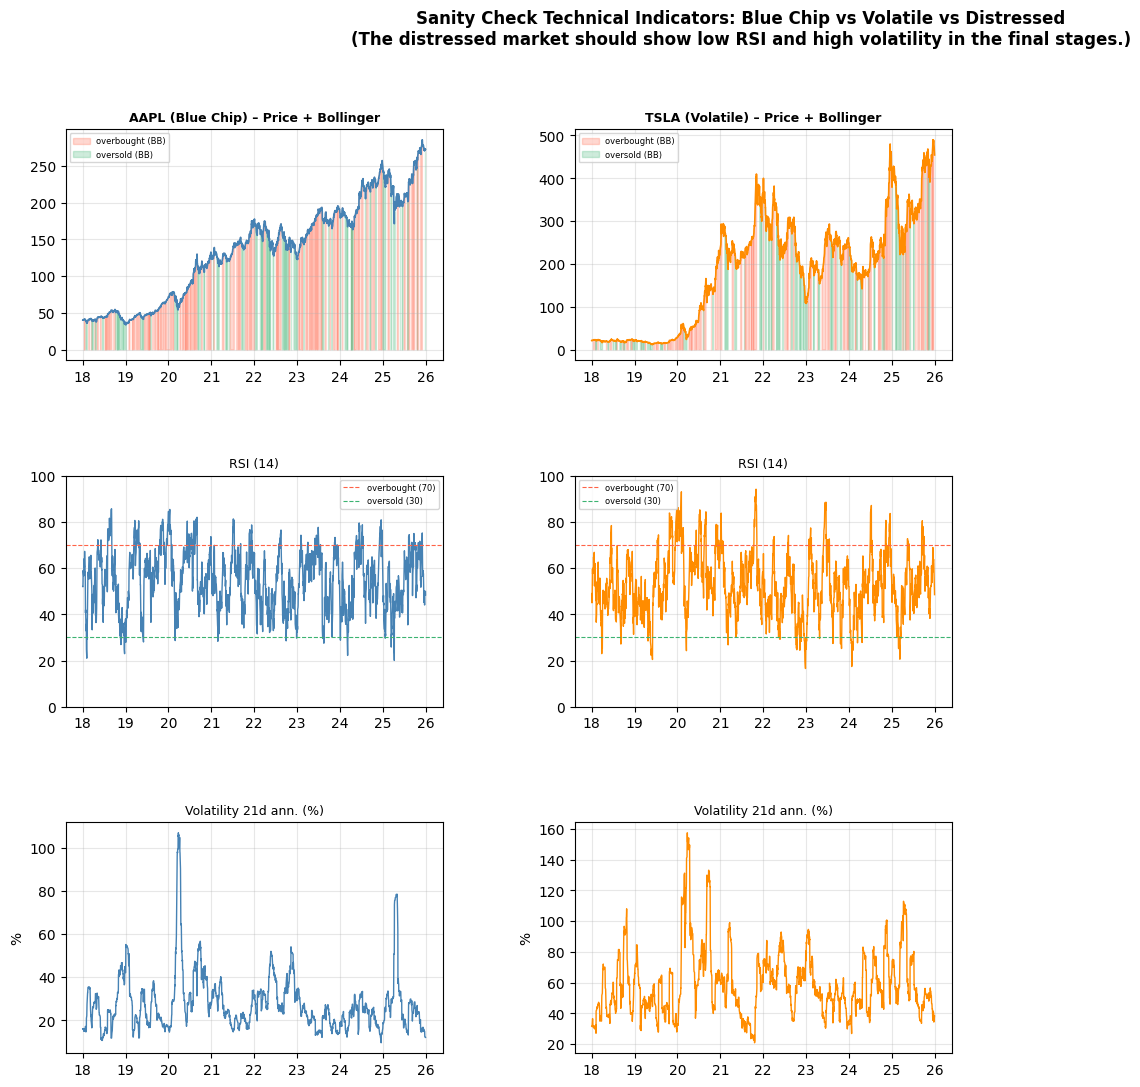

💡 Note that the distressed title (BBBY) shows:
   - Increasing volatility in the final years
   - RSI in persistent oversold territory
   - These are exactly the features the model needs to learn to read.


In [20]:
# =============================================================================
# DISPLAY: Sanity check technical indicators on 3 sample titles
# =============================================================================
# We compare a blue chip (AAPL), a volatile (TSLA) and a distressed (BBBY)
# to verify that the indicators behave consistently.
# =============================================================================

sample_tickers = [
    ('AAPL', 'steelblue',    'Blue Chip'),
    ('TSLA', 'darkorange',   'Volatile'),
    ('BBBY', 'tomato',       'Distressed'),
]

fig = plt.figure(figsize=(18, 12))
gs_main = GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.35)

for col_idx, (ticker, color, label) in enumerate(sample_tickers):
    sub = prices_long[prices_long['ticker'] == ticker].dropna(
        subset=['rsi_14','bb_position','volatility_21d']).copy()
    sub = sub[sub['date'] >= '2018-01-01']

    if sub.empty:
        continue

    # Row 0: Price with Bollinger position as background
    ax0 = fig.add_subplot(gs_main[0, col_idx])
    ax0.plot(sub['date'], sub['close'], color=color, lw=1.2)
    ax0.fill_between(sub['date'], sub['close'],
                     where=sub['bb_position'] > 0.8, alpha=0.25,
                     color='tomato', label='overbought (BB)')
    ax0.fill_between(sub['date'], sub['close'],
                     where=sub['bb_position'] < 0.2, alpha=0.25,
                     color='mediumseagreen', label='oversold (BB)')
    ax0.set_title(f'{ticker} ({label}) – Price + Bollinger', fontweight='bold', fontsize=9)
    ax0.xaxis.set_major_formatter(mdates.DateFormatter("%y"))
    ax0.legend(fontsize=6)

    # Row 1: RSI
    ax1 = fig.add_subplot(gs_main[1, col_idx])
    ax1.plot(sub['date'], sub['rsi_14'], color=color, lw=1)
    ax1.axhline(70, color='tomato', ls='--', lw=0.8, label='overbought (70)')
    ax1.axhline(30, color='mediumseagreen', ls='--', lw=0.8, label='oversold (30)')
    ax1.set_ylim(0, 100)
    ax1.set_title('RSI (14)', fontsize=9)
    ax1.legend(fontsize=6)
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%y"))

    # Row 2: Volatility realized 21d annualized
    ax2 = fig.add_subplot(gs_main[2, col_idx])
    ax2.plot(sub['date'], sub['volatility_21d'] * 100, color=color, lw=1)
    ax2.set_title('Volatility 21d ann. (%)', fontsize=9)
    ax2.set_ylabel('%')
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%y"))

plt.suptitle(
    'Sanity Check Technical Indicators: Blue Chip vs Volatile vs Distressed\n'
    '(The distressed market should show low RSI and high volatility in the final stages.)',
    fontsize=12, fontweight='bold')
plt.show()

print("💡 Note that the distressed title (BBBY) shows:")
print("   - Increasing volatility in the final years")
print("   - RSI in persistent oversold territory")
print("   - These are exactly the features the model needs to learn to read.")

---
## SECTION 4 – MERGE: Construction of the Dataset Panel

We integrate the three datasets (daily prices, annual fundamentals, monthly/daily macros)
keeping the prices dataset as a base and using 'merge_asof()' to handle
frequency mismatch without introducing look-ahead bias.

> **Constraint to respect**: for each row '(ticker, date)' in the final dataset,
> each value must have been **publicly available** before 'date'.

In [21]:
# =============================================================================
# STEP 4.1 – FUNDAMENTAL MERGE WITH merge_asof()
# =============================================================================
#
# merge_asof() semantics: for each date D in the LEFT (daily prices),
# use the RIGHT record with the most recent publish_date such that
# publish_date <= D (direction='backward').
#
# This is exactly the dataset an investor would have on that day:
# the latest published balance sheet, without knowing the future ones.
#
# TECHNICAL REQUIREMENT: LEFT must be sorted by merge key
# (date), not for (ticker, date).
# =============================================================================

# LEFT Preparation: Sorted by 'date' only
prices_sorted = prices_long.sort_values('date').copy()

# RIGHT Preparation: Only columns needed, sorted by publish_date
fund_cols = ['ticker', 'publish_date', 'revenue', 'net_income', 'ebit',
             'total_assets', 'equity', 'total_liabilities',
             'current_assets', 'current_liabilities', 'retained_earnings', 'shares']
fund_cols = [c for c in fund_cols if c in df_fundamentals.columns]

fundamentals_sorted = df_fundamentals[fund_cols].sort_values('publish_date').copy()

# Merge as-of: Forward-fill of the fundamentals
panel = pd.merge_asof(
    left      = prices_sorted,
    right     = fundamentals_sorted,
    left_on   = 'date',
    right_on  = 'publish_date',
    by        = 'ticker',      # Indipendet merge for each ticker
    direction = 'backward'     # Only data from the "past"!
)

# We reorder by (ticker, date) for time-series operations
panel = panel.sort_values(['ticker', 'date']).reset_index(drop=True)

print("✅ Merge fundamentals completed")
print(f"   Previous rows: {len(prices_sorted):,} | Raws now: {len(panel):,}")
fund_num_cols = [c for c in ['revenue','net_income','total_assets'] if c in panel.columns]
coverage = panel[fund_num_cols].notna().mean() * 100
print(f"\n   Fundamental coverage:")
for col, pct in coverage.items():
    print(f"   {col}: {pct:.1f}%")

✅ Merge fundamentals completed
   Previous rows: 119,067 | Raws now: 119,067

   Fundamental coverage:
   revenue: 36.5%
   net_income: 36.5%
   total_assets: 36.5%


In [22]:
# =============================================================================
# STEP 4.2 – MACRO DATA MERGE
# =============================================================================
# Macro data is common to all tickers → merge only on 'date', no 'by'.
# Monthly variables (CPI, unemployment) are propagated forward
# automatically from merge_asof for days without a new value.
# =============================================================================

macro_cols = ['date', 'vix', 'tbill_3m', 'treasury_10y', 'cpi_yoy',
              'term_spread', 'unemployment', 'oil_wti', 'oil_ret_1m', 'sp500_ret_1m']
macro_cols = [c for c in macro_cols if c in df_macro.columns]

macro_sorted = df_macro[macro_cols].sort_values('date').dropna(
    subset=['date']).copy()

panel = pd.merge_asof(
    left      = panel.sort_values('date'),
    right     = macro_sorted,
    on        = 'date',
    direction = 'backward'
)

panel = panel.sort_values(['ticker', 'date']).reset_index(drop=True)

print("✅ Macro data merge completed")
print(f"   Total columns in the panel: {panel.shape[1]}")
print(f"   Macro columns added:  "
      f"{[c for c in macro_cols if c != 'date' and c in panel.columns]}")

✅ Macro data merge completed
   Total columns in the panel: 55
   Macro columns added:  ['vix', 'tbill_3m', 'treasury_10y', 'cpi_yoy', 'term_spread', 'unemployment', 'oil_wti', 'oil_ret_1m', 'sp500_ret_1m']


In [23]:
# =============================================================================
# STEP 4.3 – CALCULATION FINANCIAL RATIOS AND DISTRESS INDICATORS
# =============================================================================

# 💡 THE LIFE SAVER: Function to take the column safely
def safe_col(df, col_name):
    return df[col_name] if col_name in df.columns else pd.Series(np.nan, index=df.index)

# ---- Working Capital ----
panel['working_capital'] = safe_col(panel, 'current_assets') - safe_col(panel, 'current_liabilities')
panel['x1_altman'] = panel['working_capital'] / safe_col(panel, 'total_assets').replace(0, np.nan)

# ---- Retained Earnings / Total Assets ----
panel['x2_altman'] = safe_col(panel, 'retained_earnings') / safe_col(panel, 'total_assets').replace(0, np.nan)

# ---- EBIT / Total Assets ----
panel['x3_altman'] = safe_col(panel, 'ebit') / safe_col(panel, 'total_assets').replace(0, np.nan)

# ---- Equity / Total Liabilities ----
panel['x4_altman'] = safe_col(panel, 'equity') / safe_col(panel, 'total_liabilities').replace(0, np.nan)

# ---- Revenue / Total Assets ----
panel['x5_altman'] = safe_col(panel, 'revenue') / safe_col(panel, 'total_assets').replace(0, np.nan)

# ---- Composite Z-Score ----
panel['altman_z'] = (
    1.2 * panel['x1_altman'].fillna(0) +
    1.4 * panel['x2_altman'].fillna(0) +
    3.3 * panel['x3_altman'].fillna(0) +
    0.6 * panel['x4_altman'].fillna(0) +
    1.0 * panel['x5_altman'].fillna(0)
)
# Where all 5 components are missing → Z not computable
panel.loc[panel[['x1_altman','x3_altman','x4_altman','x5_altman']].isna().all(axis=1), 'altman_z'] = np.nan

# ---- Classic financial ratios ----
panel['profit_margin'] = safe_col(panel, 'net_income') / safe_col(panel, 'revenue').replace(0, np.nan)
panel['leverage']      = safe_col(panel, 'total_liabilities') / safe_col(panel, 'total_assets').replace(0, np.nan)
panel['roa']           = safe_col(panel, 'net_income') / safe_col(panel, 'total_assets').replace(0, np.nan)
panel['roe']           = safe_col(panel, 'net_income') / safe_col(panel, 'equity').clip(lower=1)
panel['current_ratio'] = safe_col(panel, 'current_assets') / safe_col(panel, 'current_liabilities').replace(0, np.nan)

# ---- Excess return compared to risk-free ----
# tbill_3m is annual → we divide by 252 to have the daily component
panel['excess_ret_1d'] = safe_col(panel, 'log_ret_1d') - (safe_col(panel, 'tbill_3m') / 100 / 252)

# ---- Beta rolling (vs S&P 500 proxy) ----
if 'sp500_ret_1m' in panel.columns and 'log_ret_1d' in panel.columns:
    def rolling_beta(grp, window=63):
        """63-day rolling beta with respect to the market benchmark."""
        r = grp['log_ret_1d']
        m = grp['sp500_ret_1m'].ffill()
        cov = r.rolling(window, min_periods=30).cov(m)
        var = m.rolling(window, min_periods=30).var()
        return (cov / var.replace(0, np.nan)).rename('beta_63d')

    panel['beta_63d'] = panel.sort_values(
        ['ticker','date']).groupby('ticker', group_keys=False).apply(
        lambda g: rolling_beta(g))
else:
    panel['beta_63d'] = np.nan

print("✅ Financial ratios and Altman Z-Score calculated:")
ratio_cols = ['profit_margin','leverage','roa','roe','current_ratio',
              'x1_altman','x2_altman','x3_altman','x4_altman','x5_altman',
              'altman_z','excess_ret_1d','beta_63d']
print(f"   Features added: {ratio_cols}")
print(f"\n   Altman Z-Score Statistics by Category:")

if 'category' in panel.columns:
    for cat in ['blue_chip','volatile','distressed']:
        mask = panel['category'] == cat
        z_vals = panel.loc[mask, 'altman_z'].dropna()
        if len(z_vals) > 0:
            print(f"   {cat:<12}: media={z_vals.mean():.2f}, "
                  f"mediana={z_vals.median():.2f}, "
                  f"% in zona distress (<1.81)={(z_vals < 1.81).mean()*100:.1f}%")
else:
    print("   ⚠️ The 'category' column was not found. Calculations were performed, but the statistics were not printable.")

✅ Financial ratios and Altman Z-Score calculated:
   Features added: ['profit_margin', 'leverage', 'roa', 'roe', 'current_ratio', 'x1_altman', 'x2_altman', 'x3_altman', 'x4_altman', 'x5_altman', 'altman_z', 'excess_ret_1d', 'beta_63d']

   Altman Z-Score Statistics by Category:
   blue_chip   : media=2.01, mediana=1.89, % in zona distress (<1.81)=47.8%
   volatile    : media=1.17, mediana=1.25, % in zona distress (<1.81)=58.5%
   distressed  : media=0.51, mediana=0.27, % in zona distress (<1.81)=75.3%


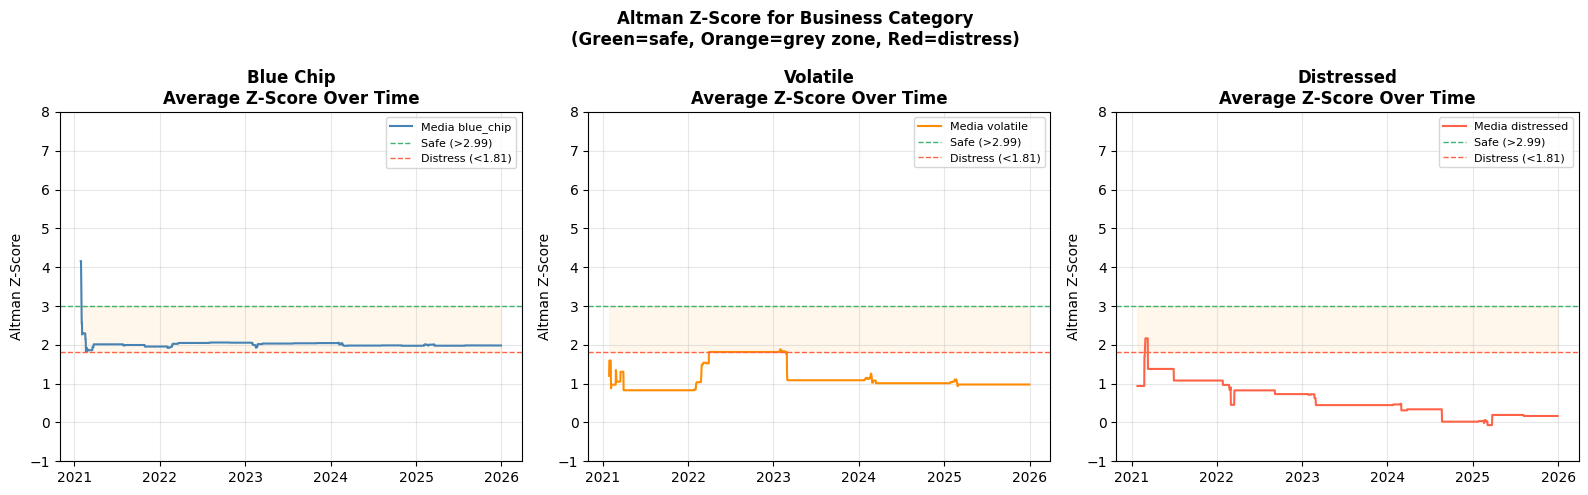


             are structurally undervalued due to the use of Accounting Equity (rather than Market Equity).


In [24]:
# =============================================================================
# VIEW: Altman Z-Score by category over time
# =============================================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (cat, color) in zip(axes, [('blue_chip','steelblue'),
                                     ('volatile','darkorange'),
                                     ('distressed','tomato')]):
    sub = panel[panel['category'] == cat].copy()
    # Daily average by category
    daily_mean = sub.groupby('date')['altman_z'].mean().reset_index()
    daily_mean = daily_mean.dropna()

    ax.plot(daily_mean['date'], daily_mean['altman_z'],
            color=color, lw=1.5, label=f'Media {cat}')
    ax.axhline(2.99, color='mediumseagreen', ls='--', lw=1, label='Safe (>2.99)')
    ax.axhline(1.81, color='tomato',         ls='--', lw=1, label='Distress (<1.81)')
    ax.fill_between(daily_mean['date'], 1.81, 2.99, alpha=0.08, color='orange')
    ax.set_title(f'{cat.replace("_"," ").title()}\nAverage Z-Score Over Time',
                 fontweight='bold')
    ax.set_ylabel('Altman Z-Score')
    ax.legend(fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.set_ylim(-1, 8)

plt.suptitle('Altman Z-Score for Business Category\n'
             '(Green=safe, Orange=grey zone, Red=distress)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n Warning: Although the risk hierarchy is correct (Blue Chip > Volatile > Distressed), all scores")
print("             are structurally undervalued due to the use of Accounting Equity (rather than Market Equity).")

---
## SECTION 5  – TARGET: Construction of target variables

We build **two types of targets** to answer different questions

**Binary classification**: *Will the price go up or down?* (Direction, up/down)

**Multi-class classification**: *By how much and in what direction?* (4 classes by intensity)
> **⚠️ Anti-leakage**:  target is built on **future** return respect to the observation date. Must be forward-looking.

In [25]:
# =============================================================================
# STEP 5.1 – First step: Future return
# =============================================================================
# fwd_ret_21d = log(Close_{t+21} / Close_{t}): this is the stock value in 21
# trading days from today.
#
# Attention: we use .shift(-FORECAST_HORIZON) that lead the future value
# on the current row. The model use just the present feature (t) to
# predict future target (t+21). There isn't look-ahead because:
# - features are built on historical data (past t)
# - target is the future value (post t)
# =============================================================================

panel['fwd_ret_21d'] = panel.groupby('ticker')['log_ret_1d'].transform(
    lambda x: x.shift(-FORECAST_HORIZON).rolling(FORECAST_HORIZON,
                                                   min_periods=FORECAST_HORIZON//2).sum()
)

# We decided to calculate also "fwd_ret_5d" in case of a future experiment
panel['fwd_ret_5d']  = panel.groupby('ticker')['log_ret_1d'].transform(
    lambda x: x.shift(-5).rolling(5, min_periods=3).sum()
)

print(f"   fwd_ret_21d: cumulative log performance of the next {FORECAST_HORIZON} days")
print(f"   fwd_ret_5d:  cumulative log performance of the next 5 days")
print(f"   Non-NaN: {panel['fwd_ret_21d'].notna().sum():,} / {len(panel):,} rows")
print(f"   Media:   {panel['fwd_ret_21d'].mean():.4f}")
print(f"   Std:     {panel['fwd_ret_21d'].std():.4f}")

   fwd_ret_21d: cumulative log performance of the next 21 days
   fwd_ret_5d:  cumulative log performance of the next 5 days
   Non-NaN: 118,269 / 119,067 rows
   Media:   0.0083
   Std:     0.1368


In [26]:
# =============================================================================
# STEP 5.2 – BINARY CLASSIFICATION TARGET
# =============================================================================
#
# target_class_binary:
#   1 =future return > 0  (the stock goes up)
#   0 = future return <= 0 (the stock goes down or doesn't move)
#
# This is the main problem classification of the project.
# The class balance is around at 50% for built
# (returns ~simmetrycal), but can deviate for distressed stock.
# =============================================================================

panel['target_binary'] = (panel['fwd_ret_21d'] > 0).astype(int)

# Category Balance Analysis
print("✅ Binary target created:")
print(f"   1 = price up (ret > 0), 0 = price down or flat (ret <= 0)")
print(f"\n   Target distribution by category:")
for cat in ['blue_chip', 'volatile', 'distressed']:
    mask = panel['category'] == cat
    sub  = panel.loc[mask, 'target_binary'].dropna()
    pct_up = sub.mean() * 100
    print(f"   {cat:<12}: {pct_up:.1f}% UP  |  {100-pct_up:.1f}% DOWN  "
          f"({len(sub):,} observations)")
print(f"\n   Total: {panel['target_binary'].mean()*100:.1f}% UP")
balance = panel['target_binary'].mean()
print(
    "   Dataset " +
    ("PERFECTLY BALANCED ✅" if 0.45 <= balance <= 0.55 else
     "ACCEPTABLE / PHYSIOLOGICAL ✅" if 0.40 <= balance <= 0.60 else
     "HEAVILY IMBALANCED ⚠️")
)

✅ Binary target created:
   1 = price up (ret > 0), 0 = price down or flat (ret <= 0)

   Target distribution by category:
   blue_chip   : 59.7% UP  |  40.3% DOWN  (78,456 observations)
   volatile    : 52.6% UP  |  47.4% DOWN  (24,486 observations)
   distressed  : 47.6% UP  |  52.4% DOWN  (16,125 observations)

   Total: 56.6% UP
   Dataset ACCEPTABLE / PHYSIOLOGICAL ✅


In [27]:
# =============================================================================
# STEP 5.3 – MULTI-CLASSES TARGET CLASSIFICATION  (4 classes)
# =============================================================================
#
# Four classes based on quartiles of future returns:
#   0 = Strong Down  (fwd_ret < Q25)   → significant decline
#   1 = Weak Down    (Q25 <= fwd_ret < 0)
#   2 = Weak Up      (0 <= fwd_ret < Q75)
#   3 = Strong Up    (fwd_ret >= Q75)   → significant increase
#
# This target provides more informations than binary classification
# but prediction is more difficult. Show also the capacity to
# build multi classes target .
# =============================================================================

# we calculate quartiles only on training data (2013-2023)
# to avoid look-ahead bias in the classification threshold!
train_mask = panel['date'] < pd.Timestamp(START_DATE_TEST)
q25 = panel.loc[train_mask, 'fwd_ret_21d'].quantile(0.25)
q75 = panel.loc[train_mask, 'fwd_ret_21d'].quantile(0.75)

print(f"   Quartile thresholds calculate on training set (2013-2023):")
print(f"   Q25 = {q25:.4f}  |  Q75 = {q75:.4f}")

def map_to_multiclass(ret):
    if pd.isna(ret):     return np.nan
    if ret < q25:        return 0   # Strong Down
    elif ret < 0:        return 1   # Weak Down
    elif ret < q75:      return 2   # Weak Up
    else:                return 3   # Strong Up

panel['target_multiclass'] = panel['fwd_ret_21d'].apply(map_to_multiclass)

print(f"\n✅ Multi-classes Target built (4 classes):")
labels = {0: 'Strong Down', 1: 'Weak Down', 2: 'Weak Up', 3: 'Strong Up'}
dist   = panel['target_multiclass'].value_counts(normalize=True).sort_index()
for cls, pct in dist.items():
    print(f"   {int(cls)} – {labels[int(cls)]:<14}: {pct*100:.1f}%")

   Quartile thresholds calculate on training set (2013-2023):
   Q25 = -0.0390  |  Q75 = 0.0596

✅ Multi-classes Target built (4 classes):
   0 – Strong Down   : 25.6%
   1 – Weak Down     : 17.5%
   2 – Weak Up       : 31.4%
   3 – Strong Up     : 25.6%


---
## SECTION 6 – VALIDATE: dataset quality analysis

Performing rigorous validation of the dataset.

In [28]:
# =============================================================================s
# STEP 6.1 – FLAG QUALITY AND MISSING DATA MANAGEMENT (PITFALL #4)
# =============================================================================

# Flag: has this stock ticker avaiable fundamentals?
panel['has_fundamentals'] = panel['revenue'].notna().astype(int)

# Flag: first quarter data for this ticker ("warm-up" period)
panel['date_rank']     = panel.groupby('ticker')['date'].rank(method='dense')
panel['is_warm_up']    = (panel['date_rank'] <= 63).astype(int)

# Flag: company in distress zone according to Altman Z
panel['is_distress_zone'] = (panel['altman_z'] < 1.81).astype(int)

# Forward fill VIX (max 5 giorni: festività, weekend long)
panel['vix'] = panel.groupby('ticker')['vix'].transform(
    lambda x: x.ffill(limit=5))

# Forward fill variabili macro mensili (CPI, unemployment, tassi)
for col in ['tbill_3m', 'treasury_10y', 'unemployment', 'cpi_yoy']:
    if col in panel.columns:
        panel[col] = panel.groupby('ticker')[col].transform(
            lambda x: x.ffill(limit=35))  # max 35 giorni (poco più di 1 mese)

# Removing unpriced rows (shouldn't be)
n_before = len(panel)
panel    = panel.dropna(subset=['close', 'log_ret_1d'])
n_after  = len(panel)

print("✅ Quality flags added and missing treatment completed:")
print(f"   Removed rows (no price or yield): {n_before - n_after:,}")
print(f"   Rows with fundamentals: {panel['has_fundamentals'].sum():,} / {len(panel):,} "
      f"({panel['has_fundamentals'].mean()*100:.1f}%)")
print(f"   Rows with warm-up period: {panel['is_warm_up'].sum():,} "
      f"({panel['is_warm_up'].mean()*100:.1f}%)")
print(f"   Rows with distress zone: {panel['is_distress_zone'].sum():,} "
      f"({panel['is_distress_zone'].mean()*100:.1f}%)")

✅ Quality flags added and missing treatment completed:
   Removed rows (no price or yield): 42
   Rows with fundamentals: 43,471 / 119,025 (36.5%)
   Rows with warm-up period: 2,604 (2.2%)
   Rows with distress zone: 24,299 (20.4%)


In [29]:
# =============================================================================
# STEP 6.2 – MISSING DATA  ANALYSIS FOR FEATURE
# =============================================================================

feature_cols = [
    'close', 'log_ret_1d', 'log_ret_5d', 'log_ret_21d',
    'rsi_14', 'macd', 'bb_position', 'atr_pct',
    'volatility_21d', 'rel_volume',
    'revenue', 'net_income', 'total_assets',
    'profit_margin', 'leverage', 'roa', 'altman_z',
    'vix', 'tbill_3m', 'term_spread', 'unemployment',
    'fwd_ret_21d', 'target_binary',
]
feature_cols = [c for c in feature_cols if c in panel.columns]

missing_df = pd.DataFrame({
    'n_missing':  panel[feature_cols].isnull().sum(),
    'pct_missing': panel[feature_cols].isnull().mean() * 100
}).sort_values('pct_missing', ascending=False)
missing_df = missing_df[missing_df['n_missing'] > 0]

print("=" * 55)
print(" MISSING DATA ANALYSIS")
print("=" * 55)
print(f"\n{len(missing_df)}/{len(feature_cols)} features with missing data:\n")
print(missing_df.round(2).to_string())

print(f"\n💡 Notes:")
print(f"   - fwd_ret_21d missing for the last ones {FORECAST_HORIZON} days "
      f"of each ticker (there is no future data) → EXPECTED")
print(f"   - Missing fundamentals for tickers not covered by SimFin→ flag 'has_fundamentals'")
print(f"   - Missing technical indicators in the warm-up phase → flag 'is_warm_up'")

 MISSING DATA ANALYSIS

17/23 features with missing data:

                n_missing  pct_missing
term_spread        115377      96.9400
altman_z            75554      63.4800
roa                 75554      63.4800
profit_margin       75554      63.4800
total_assets        75554      63.4800
revenue             75554      63.4800
leverage            75554      63.4800
net_income          75554      63.4800
unemployment        19945      16.7600
tbill_3m            18433      15.4900
log_ret_21d           840       0.7100
fwd_ret_21d           756       0.6400
rsi_14                546       0.4600
volatility_21d        378       0.3200
bb_position           336       0.2800
log_ret_5d            168       0.1400
rel_volume            126       0.1100

💡 Notes:
   - fwd_ret_21d missing for the last ones 21 days of each ticker (there is no future data) → EXPECTED
   - Missing fundamentals for tickers not covered by SimFin→ flag 'has_fundamentals'
   - Missing technical indicators in the 

In [30]:
# =============================================================================
# STEP 6.3 – SURVIVORSHIP BIAS ANALYSIS (PITFALL #3)
# =============================================================================
#
# In our dataset we try to avoid bias including failed companies.
#
# We measure the effectiveness of this mitigation by comparing
# temporale coverage across categories
# =============================================================================

print("=" * 65)
print(" SURVIVORSHIP BIAS ANALYSIS")
print("=" * 65)

coverage = panel.groupby(['ticker', 'category']).agg(
    n_days      = ('date', 'count'),
    first_date  = ('date', 'min'),
    last_date   = ('date', 'max'),
    pct_no_fund = ('has_fundamentals', lambda x: (1 - x.mean()) * 100),
    mean_z      = ('altman_z', 'mean'),
).reset_index()

coverage['years_covered'] = (coverage['last_date'] -
                              coverage['first_date']).dt.days / 365.25

coverage['survived_to_2024'] = (coverage['last_date'] >= pd.Timestamp('2024-01-01')).astype(int)

print(f"\nSummary by category:")
summary = coverage.groupby('category').agg(
    n_ticker           = ('ticker', 'count'),
    pct_survived_2024  = ('survived_to_2024', 'mean'),
    mean_years         = ('years_covered', 'mean'),
    mean_altman_z      = ('mean_z', 'mean'),
).reset_index()
summary['pct_survived_2024'] *= 100

print(summary.round(2).to_string(index=False))

n_distressed_in_train = coverage[
    (coverage['category'] == 'distressed') &
    (coverage['first_date'] <= pd.Timestamp('2015-01-01'))
]['ticker'].nunique()

print(f"\n📊 Impact on survivorship bias reduction:")
print(f"   Distressed securities with at least 2 years of training history: "
      f"{n_distressed_in_train}")
print(f"   Percentage of sample with documented failure: "
      f"{len(TICKERS_DISTRESSED)/len(TICKERS)*100:.1f}%")
print(f"\n✅ This universe reduces the optimistic bias.")

 SURVIVORSHIP BIAS ANALYSIS

Summary by category:
  category  n_ticker  pct_survived_2024  mean_years  mean_altman_z
 blue_chip        24           100.0000     12.9900         2.0000
distressed         7           100.0000      9.1600         0.5200
  volatile        11           100.0000      8.8500         1.1500

📊 Impact on survivorship bias reduction:
   Distressed securities with at least 2 years of training history: 3
   Percentage of sample with documented failure: 18.6%

✅ This universe reduces the optimistic bias.


In [31]:
# =============================================================================
# STEP 6.4 – FINAL DESCRIPTIVE STATISTICS
# =============================================================================

all_feature_cols = [
    'close', 'log_ret_1d', 'log_ret_5d', 'log_ret_21d',
    'volatility_21d', 'rsi_14', 'bb_position', 'atr_pct',
    'rel_volume', 'mom_6m', 'mom_12m',
    'revenue', 'profit_margin', 'leverage', 'roa', 'altman_z',
    'vix', 'tbill_3m', 'term_spread',
    'fwd_ret_21d', 'target_binary',
]
all_feature_cols = [c for c in all_feature_cols if c in panel.columns]

desc = panel[all_feature_cols].describe().T
desc['missing_pct'] = (panel[all_feature_cols].isnull().mean() * 100).round(1)

print("=" * 65)
print(" DESCRIPTIVE STATISTICS OF THE FINAL PANEL")
print("=" * 65)
print(f"\n  Dimension:            {panel.shape[0]:,} righe × {panel.shape[1]} colonne")
print(f"  Total ticker :          {panel['ticker'].nunique()}")
print(f"  Overall period:    {panel['date'].min().date()} → {panel['date'].max().date()}")
print(f"  Categories:              {panel['category'].value_counts().to_dict()}")
print(f"  Average days per ticker: {panel.groupby('ticker').size().mean():.0f}")
print()
print(desc[['mean','std','min','25%','50%','75%','max','missing_pct']].round(4).to_string())

 DESCRIPTIVE STATISTICS OF THE FINAL PANEL

  Dimension:            119,025 righe × 77 colonne
  Total ticker :          42
  Overall period:    2013-01-03 → 2025-12-30
  Categories:              {'blue_chip': 78432, 'volatile': 24475, 'distressed': 16118}
  Average days per ticker: 2834

                              mean                  std          min                25%                 50%                 75%                  max  missing_pct
close                     121.8115             304.0653       0.2757            27.5466             63.6000            137.4759           7,047.0000       0.0000
log_ret_1d                  0.0004               0.0304      -0.9163            -0.0092              0.0005              0.0103               1.3893       0.0000
log_ret_5d                  0.0020               0.0683      -1.6285            -0.0208              0.0033              0.0261               2.1842       0.1000
log_ret_21d                 0.0086               0.1372      -

---
## SECTION 7 –  PIPELINE CONCLUSION: Time Split

The **split train/test is time related** (is not random): data training are all
before 2024, data test are all from 2024 onwards.

> Use **casual `train_test_split`** on financing data would introduce
> **look-ahead bias** because the model would see future states during training.

In [32]:
# =============================================================================
# STEP 7.1 – FINAL COLUMN SELECTION AND SORTING
# =============================================================================

# Define column groups for final dataset
cols_keys        = ['ticker', 'date', 'category']
cols_price       = ['open', 'high', 'low', 'close', 'volume']
cols_returns     = ['log_ret_1d', 'log_ret_5d', 'log_ret_21d', 'log_ret_63d',
                    'mom_6m', 'mom_12m', 'excess_ret_1d']
cols_technical   = ['rsi_14', 'macd', 'macd_signal', 'macd_hist', 'macd_cross_up',
                    'bb_position', 'bb_width', 'atr_pct',
                    'price_to_sma50', 'price_to_sma200', 'golden_cross']
cols_volatility  = ['volatility_5d', 'volatility_21d', 'volatility_63d',
                    'vol_regime', 'rel_volume', 'intraday_range', 'beta_63d']
cols_fundamental = ['revenue', 'net_income', 'ebit', 'total_assets',
                    'equity', 'total_liabilities', 'working_capital',
                    'retained_earnings', 'shares']
cols_ratios      = ['profit_margin', 'leverage', 'roa', 'roe', 'current_ratio',
                    'x1_altman', 'x2_altman', 'x3_altman', 'x4_altman', 'x5_altman',
                    'altman_z']
cols_macro       = ['vix', 'tbill_3m', 'treasury_10y', 'cpi_yoy',
                    'term_spread', 'unemployment', 'oil_wti',
                    'oil_ret_1m', 'sp500_ret_1m']
cols_flags       = ['has_fundamentals', 'is_warm_up', 'is_distress_zone']
cols_targets     = ['fwd_ret_5d', 'fwd_ret_21d', 'target_binary', 'target_multiclass']

# Selection of the column actually present
all_cols   = (cols_keys + cols_price + cols_returns + cols_technical +
              cols_volatility + cols_fundamental + cols_ratios +
              cols_macro + cols_flags + cols_targets)
final_cols = [c for c in all_cols if c in panel.columns]

dataset_final = panel[final_cols].sort_values(
    ['ticker', 'date']).reset_index(drop=True)

print("📋 Final dataset:")
print(f"   Dimensions: {dataset_final.shape[0]:,} rows × {dataset_final.shape[1]} columns")
print(f"\n   Columns per group:")
groups = [
    ('Keys',          cols_keys),
    ('Prices',          cols_price),
    ('Return',      cols_returns),
    ('Tecnici',         cols_technical),
    ('Volatility',      cols_volatility),
    ('Fundamental',    cols_fundamental),
    ('Ratios/Altman',   cols_ratios),
    ('Macro',           cols_macro),
    ('Flag',            cols_flags),
    ('Target',          cols_targets),
]
for grp_name, grp_cols in groups:
    present = [c for c in grp_cols if c in dataset_final.columns]
    print(f"   {grp_name:<18}: {len(present)} columns → {present}")

📋 Final dataset:
   Dimensions: 119,025 rows × 68 columns

   Columns per group:
   Keys              : 3 columns → ['ticker', 'date', 'category']
   Prices            : 5 columns → ['open', 'high', 'low', 'close', 'volume']
   Return            : 7 columns → ['log_ret_1d', 'log_ret_5d', 'log_ret_21d', 'log_ret_63d', 'mom_6m', 'mom_12m', 'excess_ret_1d']
   Tecnici           : 11 columns → ['rsi_14', 'macd', 'macd_signal', 'macd_hist', 'macd_cross_up', 'bb_position', 'bb_width', 'atr_pct', 'price_to_sma50', 'price_to_sma200', 'golden_cross']
   Volatility        : 7 columns → ['volatility_5d', 'volatility_21d', 'volatility_63d', 'vol_regime', 'rel_volume', 'intraday_range', 'beta_63d']
   Fundamental       : 8 columns → ['revenue', 'net_income', 'total_assets', 'equity', 'total_liabilities', 'working_capital', 'retained_earnings', 'shares']
   Ratios/Altman     : 11 columns → ['profit_margin', 'leverage', 'roa', 'roe', 'current_ratio', 'x1_altman', 'x2_altman', 'x3_altman', 'x4_altman'

In [33]:
# =============================================================================
# STEP 7.2 – TIME SPLIT TRAIN / TEST
# =============================================================================
#
# STRICT RULE: no test set observation must be used
# during training. The split is based on 'date', not on 'ticker'.
#
# Training: 2013-01-01 → 2023-12-31
# Test:      2024-01-01 → 2025-12-31
#
# Note: the last FORECAST_HORIZON rows of every ticker in train set
# will have NaN as target (future is in test set).
# These rows are removed from the effective train set.
# =============================================================================

split_date = pd.Timestamp(START_DATE_TEST)

df_train = dataset_final[dataset_final['date'] < split_date].copy()
df_test  = dataset_final[dataset_final['date'] >= split_date].copy()

# Removing rows whitout target from training set
df_train_clean = df_train.dropna(subset=['target_binary'])
df_test_clean  = df_test.dropna(subset=['target_binary'])

print("📊 Split Time Train / Test:")
print(f"\n   TRAINING SET:")
print(f"   Period:       {df_train['date'].min().date()} → {df_train['date'].max().date()}")
print(f"   Total rows:  {len(df_train):,}")
print(f"   Rows with target: {len(df_train_clean):,}")
print(f"   Ticker:        {df_train['ticker'].nunique()}")
print(f"   Category:     {df_train['category'].value_counts().to_dict()}")

print(f"\n   TEST SET:")
print(f"   Period:       {df_test['date'].min().date()} → {df_test['date'].max().date()}")
print(f"   Total rows:  {len(df_test):,}")
print(f"   Rows with target: {len(df_test_clean):,}")
print(f"   Ticker:        {df_test['ticker'].nunique()}")
print(f"   Category:     {df_test['category'].value_counts().to_dict()}")

print(f"\n   Train/test ratio: "
      f"{len(df_train_clean)/(len(df_train_clean)+len(df_test_clean))*100:.1f}% "
      f"/ {len(df_test_clean)/(len(df_train_clean)+len(df_test_clean))*100:.1f}%")

📊 Split Time Train / Test:

   TRAINING SET:
   Period:       2013-01-03 → 2023-12-29
   Total rows:  97,983
   Rows with target: 97,983
   Ticker:        42
   Category:     {'blue_chip': 66408, 'volatile': 18964, 'distressed': 12611}

   TEST SET:
   Period:       2024-01-02 → 2025-12-30
   Total rows:  21,042
   Rows with target: 21,042
   Ticker:        42
   Category:     {'blue_chip': 12024, 'volatile': 5511, 'distressed': 3507}

   Train/test ratio: 82.3% / 17.7%
